# EDA de producción de biocombustibles

**Proyecto BCR · Lab 2 · Épica E3 (SCRUM-19, corregido en SCRUM-45)**

Análisis exploratorio del target: producción mensual de biodiesel (tn) y de
bioetanol total, de maíz y de caña (m³).

El notebook está dividido en **dos partes** con reglas distintas sobre qué
datos pueden mirar:

| Parte | Qué hace | Datos que usa |
|---|---|---|
| **A. Descriptiva** | calidad de datos, faltantes, unidades, entender la serie | toda la muestra |
| **B. Decisiones para el modelo** | outliers, estacionalidad, estacionariedad, transformación, quiebres | solo hasta **agosto 2021** |

El backtest del protocolo (SCRUM-43) empieza en **septiembre 2021**. Todo lo
que alimenta una decisión de modelado (qué transformar, qué tratar como
outlier, qué diferenciar) se calcula con datos anteriores a esa fecha, para
que el error del backtest y del holdout no salga optimista.

Ventana de entrenamiento de cada serie (primer mes con datos representativos,
la usa `scripts/evaluacion.py`). Elegir el inicio no depende del período de
evaluación: el bioetanol arranca en 2013 por la producción casi nula de
2009 a 2012.

| Serie | Unidad | Inicio entrenamiento |
|---|---|---|
| biodiesel | toneladas | 2008-01 |
| bioetanol total | m³ | 2013-01 |
| bioetanol maíz | m³ | 2012-09 |
| bioetanol caña | m³ | 2013-01 |

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

plt.rcParams["figure.figsize"] = (12, 4)

bd = pd.read_csv("../data/produccion_biodiesel.csv", parse_dates=["fecha"]).set_index("fecha")
be = pd.read_csv("../data/produccion_bioetanol.csv", parse_dates=["fecha"]).set_index("fecha")

# (serie, unidad, inicio de entrenamiento)
SERIES = {
    "biodiesel":       (bd["produccion_tn"],        "toneladas", "2008-01"),
    "bioetanol_total": (be["produccion_total_m3"],  "m³",        "2013-01"),
    "bioetanol_maiz":  (be["produccion_maiz_m3"],   "m³",        "2012-09"),
    "bioetanol_cana":  (be["produccion_cana_m3"],   "m³",        "2013-01"),
}

# Límite de la Parte B: último mes antes del backtest (SCRUM-43).
INICIO_BACKTEST = pd.Timestamp("2021-09-01")
FIN_DECISIONES = pd.Timestamp("2021-08-01")
# Inicio del holdout (últimos 12 meses), solo para sombrear gráficos de la Parte A.
INICIO_HOLDOUT = pd.Timestamp("2025-09-01")


def ventana_decision(s, ini):
    """Serie desde su inicio de entrenamiento hasta agosto 2021, mensual."""
    s = s[(s.index >= ini) & (s.index <= FIN_DECISIONES)]
    return s.asfreq("MS")


for nom, (s, u, ini) in SERIES.items():
    w = ventana_decision(s, ini)
    print(f"{nom:16s}: muestra {s.index.min():%Y-%m} a {s.index.max():%Y-%m} | "
          f"ventana de decisión {w.index.min():%Y-%m} a {w.index.max():%Y-%m} ({len(w)} meses)")

biodiesel       : muestra 2008-01 a 2026-08 | ventana de decisión 2008-01 a 2021-08 (164 meses)
bioetanol_total : muestra 2009-11 a 2026-08 | ventana de decisión 2013-01 a 2021-08 (104 meses)
bioetanol_maiz  : muestra 2009-11 a 2026-08 | ventana de decisión 2012-09 a 2021-08 (108 meses)
bioetanol_cana  : muestra 2009-11 a 2026-08 | ventana de decisión 2013-01 a 2021-08 (104 meses)


# Parte A. Descriptiva (toda la muestra)

Esta parte puede mirar toda la serie porque **no toma decisiones**: sirve
para conocer los datos (calidad, faltantes, unidades, forma general). Nada
de lo que sale de acá se usa para elegir transformaciones, outliers o
quiebres.

## A1. Calidad de datos

Por serie: rango de fechas, meses faltantes dentro del rango, meses con
producción cero y valores extremos en su unidad.

In [2]:
filas = []
for nom, (s, u, ini) in SERIES.items():
    grilla = pd.date_range(s.index.min(), s.index.max(), freq="MS")
    filas.append({
        "serie": nom, "unidad": u,
        "desde": f"{s.index.min():%Y-%m}", "hasta": f"{s.index.max():%Y-%m}",
        "meses": len(s),
        "faltantes": int(grilla.difference(s.index).size),
        "nulos": int(s.isna().sum()),
        "ceros": int((s == 0).sum()),
        "duplicados": int(s.index.duplicated().sum()),
        "mínimo": round(float(s[s > 0].min()), 1),
        "máximo": round(float(s.max()), 1),
    })
calidad = pd.DataFrame(filas).set_index("serie")
calidad

,unidad,desde,hasta,meses,faltantes,nulos,ceros,duplicados,mínimo,máximo
serie,,,,,,,,,,
biodiesel,toneladas,2008-01,2026-08,224,0,0,0,0,9058.4,308897.0
bioetanol_total,m³,2009-11,2026-08,202,0,0,0,0,771.0,139521.0
bioetanol_maiz,m³,2009-11,2026-08,202,0,0,34,0,3373.0,74649.6
bioetanol_cana,m³,2009-11,2026-08,202,0,0,0,0,268.2,67782.6


Las cuatro series están completas: sin meses faltantes, nulos ni fechas
duplicadas dentro de su rango. Los mínimos de bioetanol corresponden al
arranque de 2009 a 2012, que queda fuera de la ventana de entrenamiento.

## A2. Producción en nivel y períodos del protocolo

Cada serie en nivel con los tres tramos del protocolo: ventana de decisión
(hasta agosto 2021), backtest (septiembre 2021 a agosto 2025) y holdout
(últimos 12 meses). La línea punteada gris marca **noviembre 2025, el mes
donde la producción cambia de nivel** (no es la última data ni una
publicación del IACA). Es una **observación descriptiva**: cae dentro del
holdout, así que no se usa para ninguna decisión del modelo (ver B6).

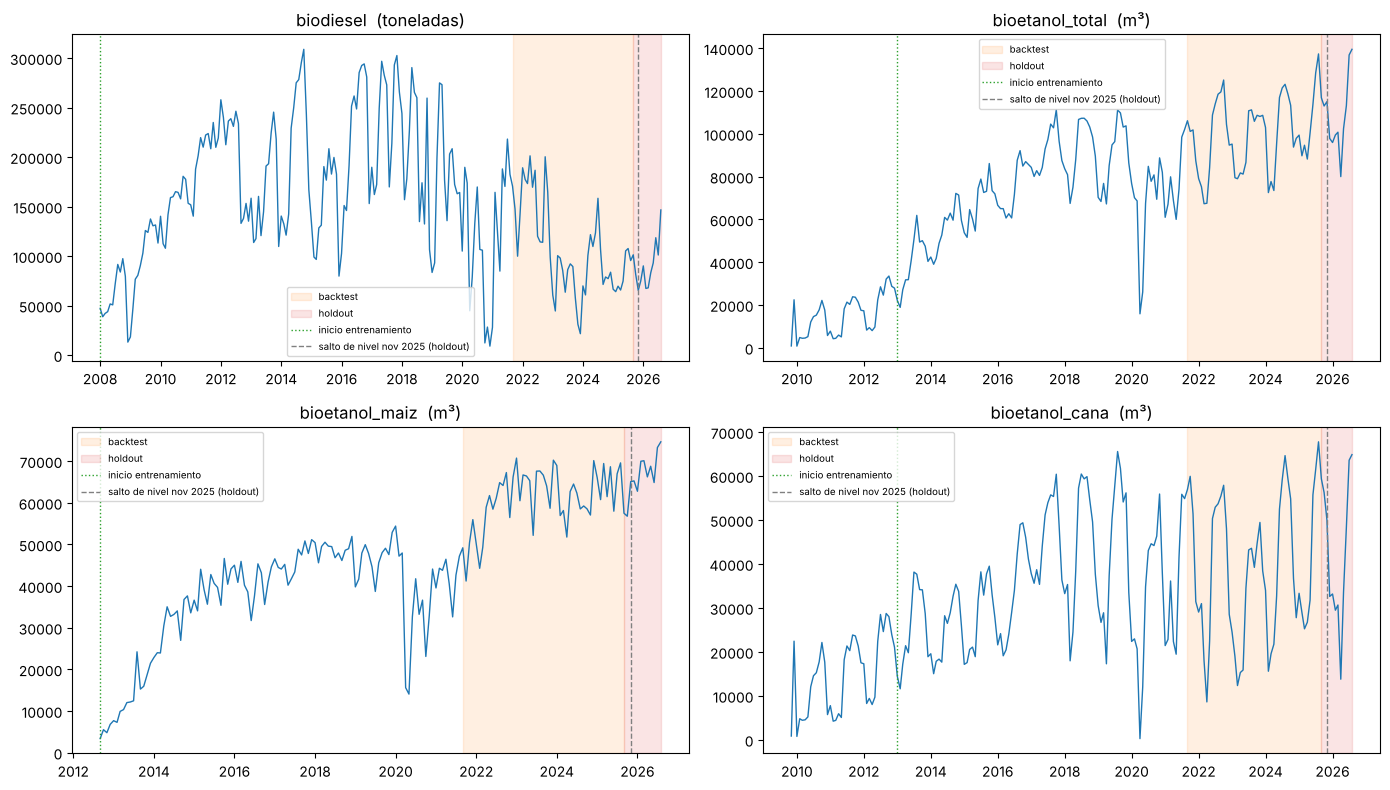

In [3]:
CORTE_NOV25 = pd.Timestamp("2025-11-01")
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, (nom, (s, u, ini)) in zip(axes.ravel(), SERIES.items()):
    s = s[s > 0]
    ax.plot(s.index, s.values, lw=1)
    ax.axvspan(INICIO_BACKTEST, INICIO_HOLDOUT, color="tab:orange", alpha=0.12, label="backtest")
    ax.axvspan(INICIO_HOLDOUT, s.index.max(), color="tab:red", alpha=0.12, label="holdout")
    ax.axvline(pd.Timestamp(ini), color="tab:green", ls=":", lw=1, label="inicio entrenamiento")
    ax.axvline(CORTE_NOV25, color="gray", ls="--", lw=1, label="salto de nivel nov 2025 (holdout)")
    ax.set_title(f"{nom}  ({u})"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

## A3. Índice base 2013 = 100

Es la representación que usa BCR para el IACA: cada serie como índice con
promedio 2013 = 100, para comparar las cuatro en la misma escala relativa.

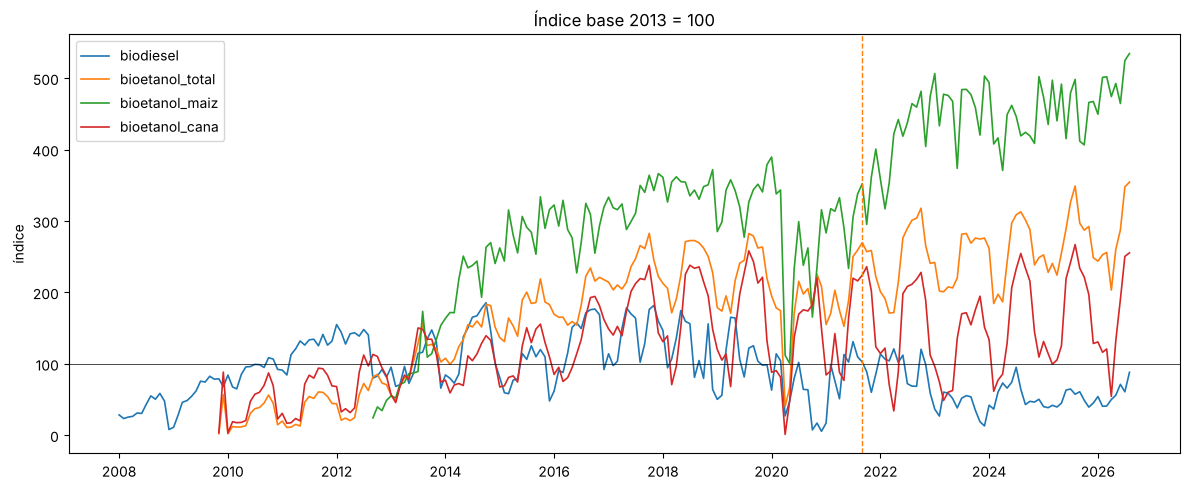

In [4]:
fig, ax = plt.subplots(figsize=(12, 5))
for nom, (s, u, ini) in SERIES.items():
    s = s[s > 0]
    base = s[s.index.year == 2013].mean()
    idx = s / base * 100
    ax.plot(idx.index, idx.values, lw=1.2, label=nom)
ax.axhline(100, color="k", lw=0.5)
ax.axvline(INICIO_BACKTEST, color="tab:orange", ls="--", lw=1)
ax.set_title("Índice base 2013 = 100"); ax.set_ylabel("índice"); ax.legend()
plt.tight_layout(); plt.show()

## A4. Logaritmo y variación mensual

El log y la variación mensual en log (`Δ log`, aproximadamente el cambio
porcentual mes a mes), para ver la forma de cada serie. La decisión de qué
transformación usar se toma en B5, solo con la ventana de decisión.

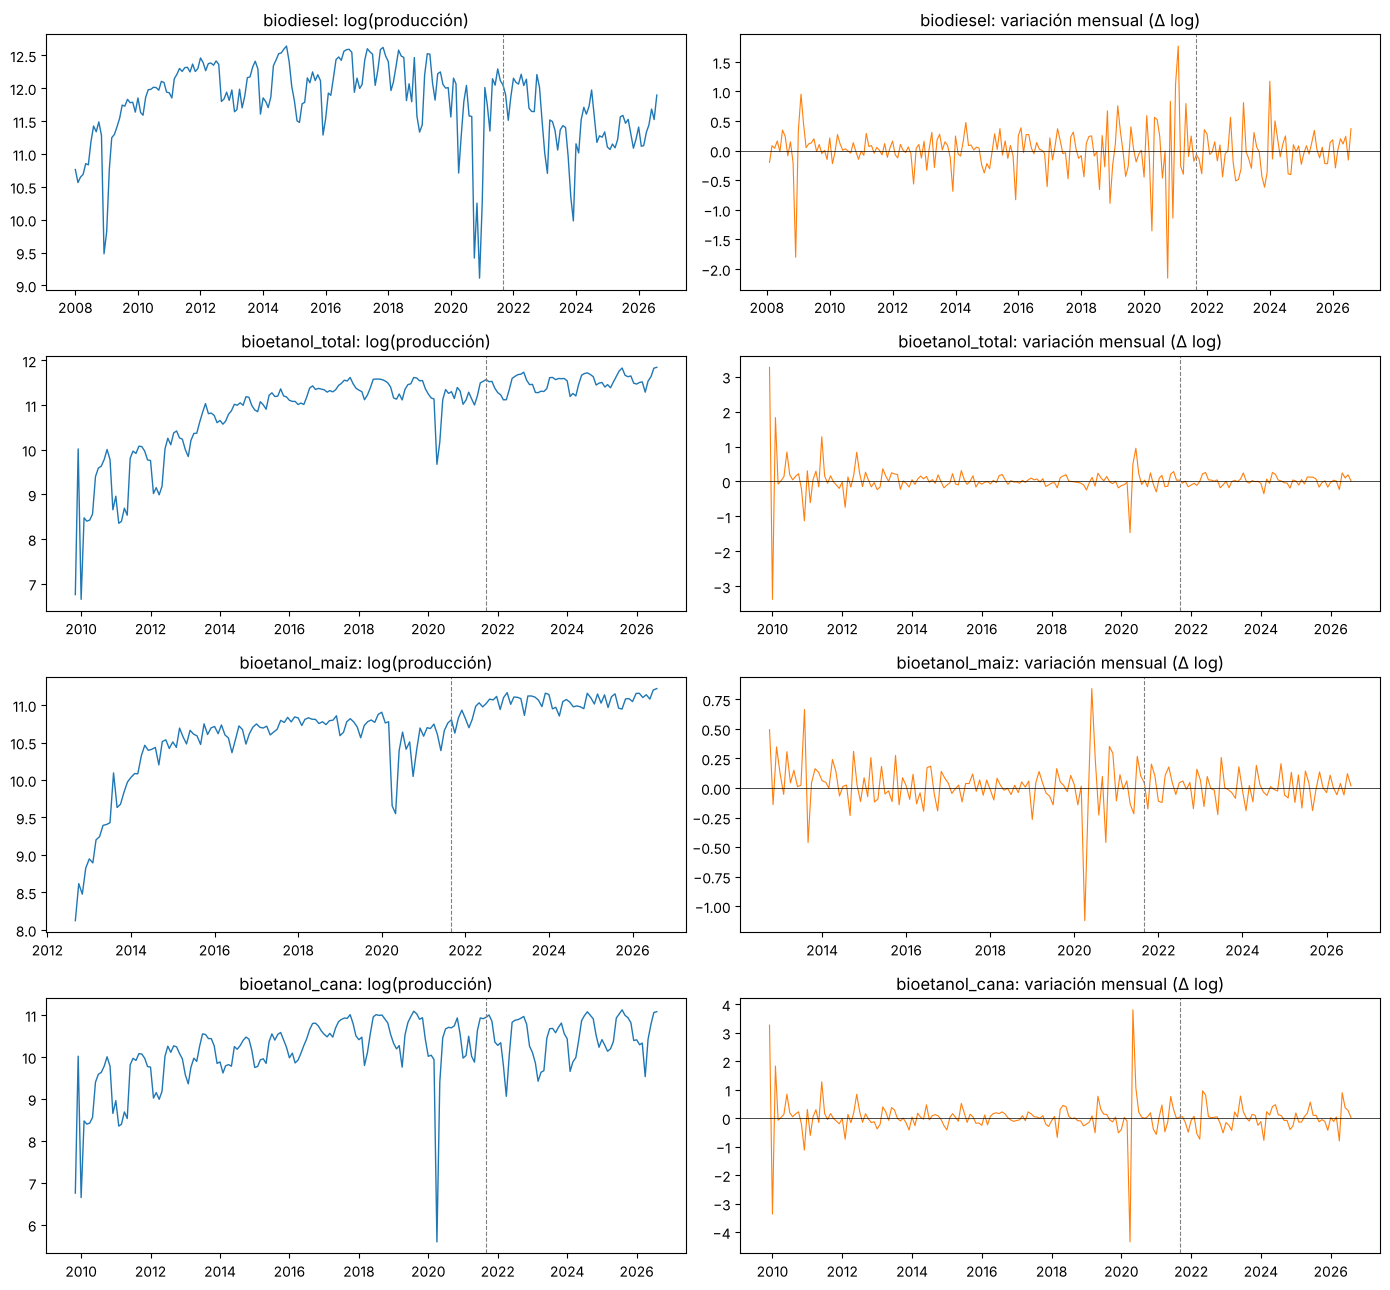

In [5]:
fig, axes = plt.subplots(4, 2, figsize=(14, 13))
for fila, (nom, (s, u, ini)) in zip(axes, SERIES.items()):
    s = s[s > 0]
    logs = np.log(s)
    dlog = logs.diff()
    fila[0].plot(logs.index, logs.values, lw=1)
    fila[0].set_title(f"{nom}: log(producción)")
    fila[1].plot(dlog.index, dlog.values, lw=0.8, color="tab:orange")
    fila[1].axhline(0, color="k", lw=0.5)
    fila[1].set_title(f"{nom}: variación mensual (Δ log)")
    for ax in fila:
        ax.axvline(INICIO_BACKTEST, color="gray", ls="--", lw=0.8)
plt.tight_layout(); plt.show()

## A5. Crecimiento de largo plazo

El crecimiento del bioetanol se mide año contra año, no contra el mes de
arranque (noviembre 2009), que es un piso artificial.

In [6]:
bt = be["produccion_total_m3"]; bt = bt[bt > 0]
m2010 = bt[bt.index.year == 2010].mean()
m2025 = bt[bt.index.year == 2025].mean()
print(f"Bioetanol total, media mensual 2010: {m2010:,.0f} m³")
print(f"Bioetanol total, media mensual 2025: {m2025:,.0f} m³")
print(f"Crecimiento 2010 a 2025: x{m2025/m2010:.1f}")
print(f"(contra el mes de arranque nov 2009, {bt.iloc[0]:,.0f} m³, daría un engañoso x{m2025/bt.iloc[0]:.0f})")

Bioetanol total, media mensual 2010: 10,411 m³
Bioetanol total, media mensual 2025: 107,907 m³
Crecimiento 2010 a 2025: x10.4
(contra el mes de arranque nov 2009, 858 m³, daría un engañoso x126)


# Parte B. Decisiones para el modelo (solo hasta agosto 2021)

Todo lo que sigue usa `ventana_decision(serie, inicio)`: desde el inicio de
entrenamiento de cada serie hasta **agosto 2021**. Ningún número de esta
parte depende de meses del backtest ni del holdout.

## B1. Outliers

Outlier = residuo STL (en log, robusto) mayor a 3 desvíos, calculado sobre la
ventana de decisión.

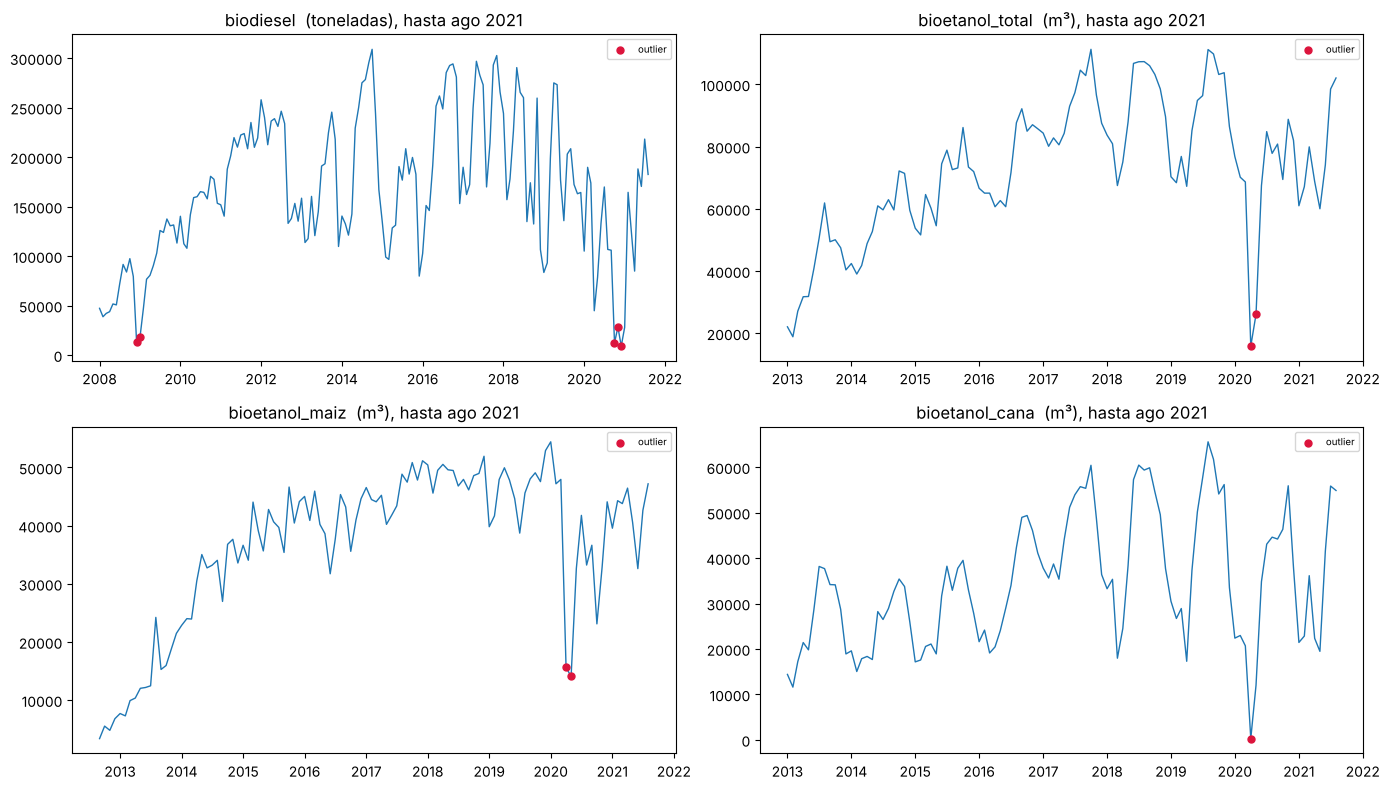

biodiesel       : outliers: ['2008-12', '2009-01', '2020-10', '2020-11', '2020-12']
bioetanol_total : outliers: ['2020-04', '2020-05']
bioetanol_maiz  : outliers: ['2020-04', '2020-05']
bioetanol_cana  : outliers: ['2020-04']


In [7]:
def outliers_stl(w, k=3.0):
    """Fechas con residuo STL (en log) mayor a k desvíos."""
    res = STL(np.log(w), period=12, robust=True).fit().resid
    z = (res - res.mean()) / res.std()
    return w.index[np.abs(z) > k]

OUTLIERS = {}
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, (nom, (s, u, ini)) in zip(axes.ravel(), SERIES.items()):
    w = ventana_decision(s, ini)
    out = outliers_stl(w)
    OUTLIERS[nom] = out
    ax.plot(w.index, w.values, lw=1)
    ax.scatter(out, w.loc[out], color="crimson", zorder=5, s=25, label="outlier")
    ax.set_title(f"{nom}  ({u}), hasta ago 2021"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

for nom, out in OUTLIERS.items():
    print(f"{nom:16s}: outliers:", [d.strftime('%Y-%m') for d in out])

Los outliers de la ventana son el shock de pandemia (abril y mayo 2020 en
bioetanol, octubre a diciembre 2020 en biodiesel) y la crisis de fines de
2008 en biodiesel. Ninguno depende del backtest: el diciembre 2023 que
marcaba la versión anterior de este notebook solo aparecía al calcular el STL
con toda la muestra, y ya no se usa.

## B2. Estacionalidad

Fuerza estacional = 1 − var(resto) / var(estacional + resto), con STL robusto,
en log y en nivel. Se reporta sobre la ventana completa y sobre **2013 a
2019** (sin el shock de 2020 y 2021, que infla el residuo). Las dos ventanas
son anteriores al backtest.

In [8]:
def fuerza_estacional(x):
    r = STL(x, period=12, robust=True).fit()
    return max(0.0, 1 - r.resid.var() / (r.seasonal + r.resid).var())

filas = []
for nom, (s, u, ini) in SERIES.items():
    w = ventana_decision(s, ini)
    w19 = w[(w.index.year >= 2013) & (w.index.year <= 2019)]
    filas.append({
        "serie": nom,
        "log, ventana": fuerza_estacional(np.log(w)),
        "nivel, ventana": fuerza_estacional(w),
        "log, 2013 a 2019": fuerza_estacional(np.log(w19)),
        "nivel, 2013 a 2019": fuerza_estacional(w19),
    })
FUERZA = pd.DataFrame(filas).set_index("serie").round(3)
FUERZA

,"log, ventana","nivel, ventana","log, 2013 a 2019","nivel, 2013 a 2019"
serie,,,,
biodiesel,0.331,0.361,0.681,0.699
bioetanol_total,0.498,0.618,0.673,0.761
bioetanol_maiz,0.073,0.072,0.221,0.352
bioetanol_cana,0.000,0.797,0.809,0.837


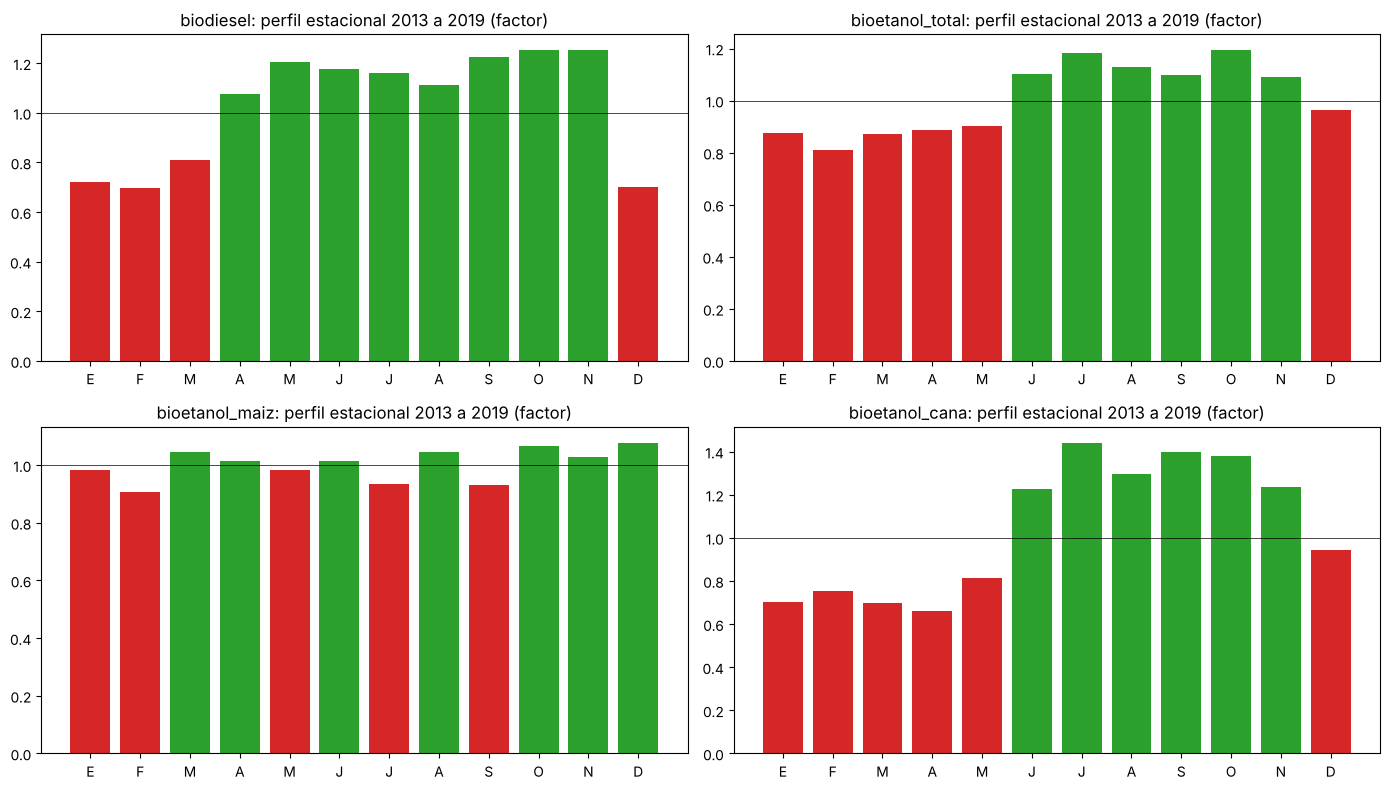

In [9]:
# perfil estacional promedio por mes (factor multiplicativo), ventana 2013 a 2019
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
meses = ["E","F","M","A","M","J","J","A","S","O","N","D"]
for ax, (nom, (s, u, ini)) in zip(axes.ravel(), SERIES.items()):
    w = ventana_decision(s, ini)
    w = w[(w.index.year >= 2013) & (w.index.year <= 2019)]
    comp = STL(np.log(w), period=12, robust=True).fit()
    fac = np.exp(comp.seasonal).groupby(comp.seasonal.index.month).mean()
    ax.bar(range(1, 13), fac.values, color=["tab:green" if v >= 1 else "tab:red" for v in fac.values])
    ax.axhline(1, color="k", lw=0.5)
    ax.set_xticks(range(1, 13)); ax.set_xticklabels(meses)
    ax.set_title(f"{nom}: perfil estacional 2013 a 2019 (factor)")
plt.tight_layout(); plt.show()

**Lectura (columna 2013 a 2019, en log):**

- **Biodiesel: fuerte** (0.68). Sobre la ventana completa baja a 0.33 por el
  shock de 2020.
- **Bioetanol caña: fuerte** (0.81), por la zafra. Sobre la ventana completa en
  log da 0.00 porque abril 2020 (268 m³) domina el residuo; en nivel da
  0.80.
- **Bioetanol total: fuerte a moderada** (0.67), arrastrada por la caña.
- **Bioetanol maíz: leve** (0.22): producción casi plana durante el año.

La versión anterior daba 0.34 para el total y 0.22 para biodiesel porque
calculaba el STL con toda la muestra, incluyendo el backtest.

## B3. Autocorrelación (ACF / PACF)

Sobre la variación mensual (`Δ log`) de la ventana de decisión. Orienta los
órdenes AR/MA de los modelos.

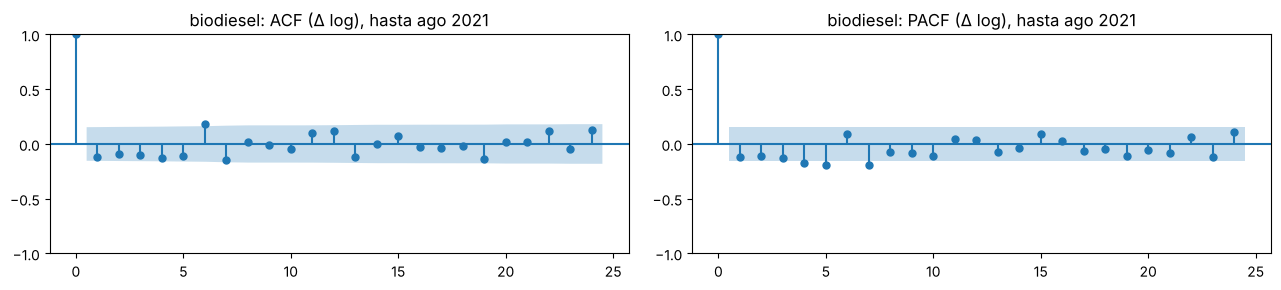

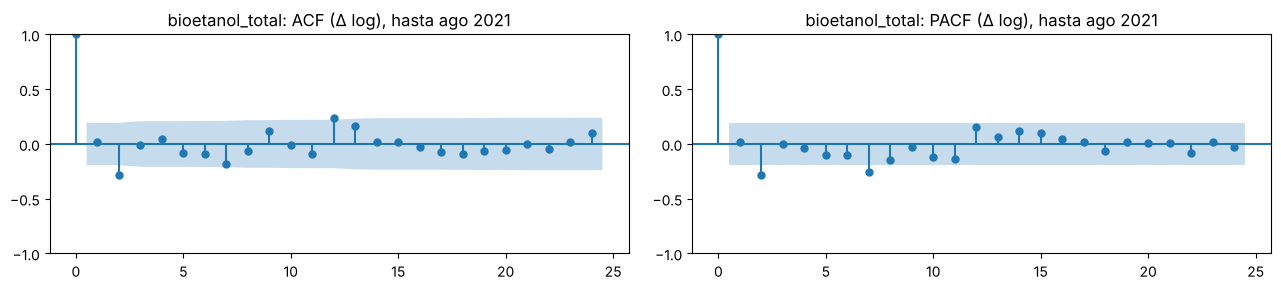

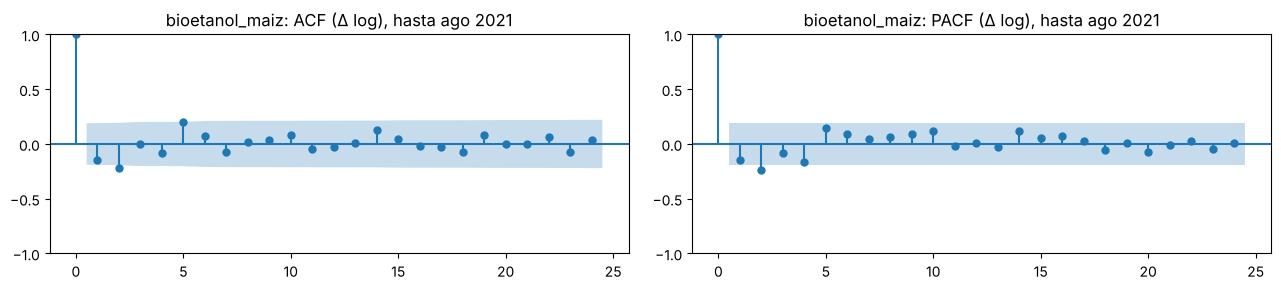

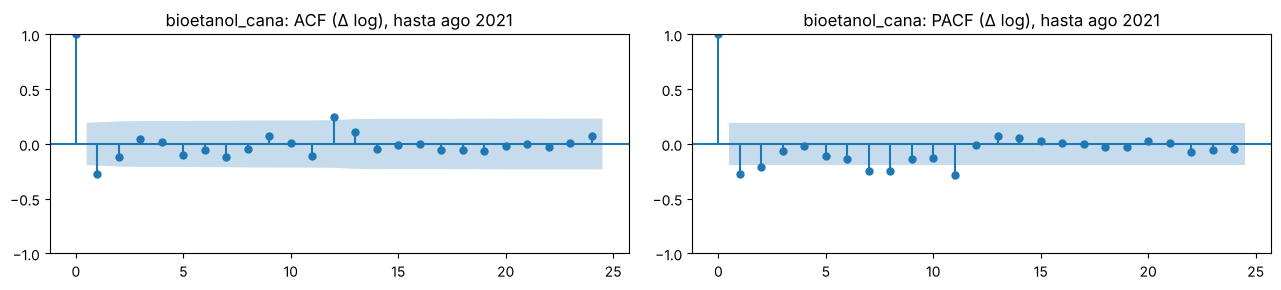

In [10]:
for nom, (s, u, ini) in SERIES.items():
    dlog = np.log(ventana_decision(s, ini)).diff().dropna()
    fig, ax = plt.subplots(1, 2, figsize=(13, 3))
    plot_acf(dlog, lags=24, ax=ax[0]); ax[0].set_title(f"{nom}: ACF (Δ log), hasta ago 2021")
    plot_pacf(dlog, lags=24, ax=ax[1], method="ywm"); ax[1].set_title(f"{nom}: PACF (Δ log), hasta ago 2021")
    plt.tight_layout(); plt.show()

## B4. Estacionariedad: ADF y KPSS

Los dos tests tienen hipótesis nulas opuestas, por eso se leen juntos:

- **ADF**: H0 = raíz unitaria. p < 0.05 indica estacionariedad.
- **KPSS**: H0 = estacionaria. p < 0.05 indica que no lo es.

| ADF | KPSS | Lectura |
|---|---|---|
| rechaza | no rechaza | estacionaria |
| no rechaza | rechaza | no estacionaria |
| rechaza | rechaza | contradictorio (suele indicar quiebres, persistencia alta o estacionalidad fuerte) |
| no rechaza | no rechaza | no concluyente |

Se corren en la ventana de decisión sobre el log en nivel, con constante
(`c`) y con constante y tendencia (`ct`), y sobre `Δ log` solo con constante,
porque al diferenciar la tendencia ya se fue. KPSS solo tabula
p entre 0.01 y 0.10: un valor de 0.010 significa "0.01 o menos" y uno de
0.100 significa "0.10 o más".

In [11]:
def lectura(p_adf, p_kpss, alfa=0.05):
    adf_rech, kpss_rech = p_adf < alfa, p_kpss < alfa
    if adf_rech and not kpss_rech:
        return "estacionaria"
    if not adf_rech and kpss_rech:
        return "no estacionaria"
    if adf_rech and kpss_rech:
        return "contradictorio"
    return "no concluyente"

filas = []
for nom, (s, u, ini) in SERIES.items():
    logw = np.log(ventana_decision(s, ini))
    for transf, x in [("log", logw), ("Δ log", logw.diff().dropna())]:
        for reg in (["c", "ct"] if transf == "log" else ["c"]):
            p_adf = adfuller(x, regression=reg, autolag="AIC")[1]
            p_kpss = kpss(x, regression=reg, nlags="auto")[1]
            filas.append({"serie": nom, "transformación": transf, "término": reg,
                          "n": len(x), "p ADF": round(p_adf, 3), "p KPSS": round(p_kpss, 3),
                          "lectura": lectura(p_adf, p_kpss)})
ESTACIONARIEDAD = pd.DataFrame(filas).set_index(["serie", "transformación", "término"])
ESTACIONARIEDAD

/tmp/ipykernel_207/1606750356.py:17: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  p_kpss = kpss(x, regression=reg, nlags="auto")[1]
/tmp/ipykernel_207/1606750356.py:17: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  p_kpss = kpss(x, regression=reg, nlags="auto")[1]
/tmp/ipykernel_207/1606750356.py:17: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  p_kpss = kpss(x, regression=reg, nlags="auto")[1]
/tmp/ipykernel_207/1606750356.py:17: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  p_kpss = kpss(x, regression=re

n  p ADF  p KPSS         lectura
serie           transformación término                                    
biodiesel       log            c        164  0.000   0.087    estacionaria
                               ct       164  0.001   0.010  contradictorio
                Δ log          c        163  0.000   0.100    estacionaria
bioetanol_total log            c        104  0.007   0.010  contradictorio
                               ct       104  0.020   0.010  contradictorio
                Δ log          c        103  0.000   0.100    estacionaria
bioetanol_maiz  log            c        108  0.000   0.010  contradictorio
                               ct       108  0.014   0.010  contradictorio
                Δ log          c        107  0.000   0.051    estacionaria
bioetanol_cana  log            c        104  0.000   0.100    estacionaria
                               ct       104  0.000   0.085    estacionaria
                Δ log          c        103  0.000   0.100    estacionaria

**Lectura** (especificación con constante, `c`; la de tendencia, `ct`,
se comenta donde cambia):

- **Biodiesel**: en log es **estacionaria** (ADF 0.000, KPSS 0.087). Con
  tendencia KPSS rechaza (0.010), así que no hay evidencia de una tendencia
  determinística estable.
- **Bioetanol caña**: en log es **estacionaria** (ADF 0.000, KPSS 0.100), y
  también con tendencia.
- **Bioetanol total**: en log es **contradictorio** (ADF 0.007, KPSS 0.010):
  ADF rechaza la raíz unitaria pero KPSS rechaza estacionariedad. Es lo
  esperable con el crecimiento escalonado de 2013 a 2021.
- **Bioetanol maíz**: en log es **contradictorio** (ADF 0.000, KPSS 0.010),
  por el mismo motivo.
- **Δ log**: ADF rechaza en las cuatro (p máximo 0.000). KPSS no rechaza
  en biodiesel, total y caña (0.100 o más), y en maíz queda en el límite
  (0.051).

La versión anterior decía que en nivel las series no son estacionarias con
p entre 0.43 y 0.51; ese número no aparecía en ninguna salida y la tabla de
ADF ya mostraba lo contrario en tres de las cuatro series.

**Implicancia para el modelado:** en total y maíz la diferenciación (`d=1`)
es la opción segura. En biodiesel y caña el log en nivel con componente
estacional es viable, así que conviene probar `d=0` y `d=1` en el
walk-forward (SCRUM-29) en lugar de fijar `d=1` de antemano. Estos tests no
contemplan raíz unitaria estacional; la diferencia estacional queda como
otra opción a comparar en el backtest.

## B5. Transformación: log o nivel

Criterio: si la dispersión crece con el nivel, conviene el log (esquema
multiplicativo); si no, se puede modelar en nivel (aditivo). Se mide la
correlación entre la media y el desvío de cada año calendario completo de la
ventana de decisión, en nivel y en log. Una correlación positiva en nivel que
el log lleva cerca de cero indica que el log es la transformación adecuada.
Son 8 a 14 años por serie, así que es una guía, no un test.

In [12]:
filas = []
for nom, (s, u, ini) in SERIES.items():
    w = ventana_decision(s, ini)
    completos = w.groupby(w.index.year).size() == 12
    anios = completos[completos].index
    g = w[w.index.year.isin(anios)].groupby(lambda d: d.year)
    gl = np.log(w[w.index.year.isin(anios)]).groupby(lambda d: d.year)
    media = g.mean()
    filas.append({"serie": nom, "años": len(anios),
                  "corr(media, desvío) en nivel": round(media.corr(g.std()), 2),
                  "corr(media, desvío) en log": round(media.corr(gl.std()), 2)})
TRANSF = pd.DataFrame(filas).set_index("serie")
TRANSF

,años,"corr(media, desvío) en nivel","corr(media, desvío) en log"
serie,,,
biodiesel,13,0.49,-0.66
bioetanol_total,8,0.01,-0.54
bioetanol_maiz,8,-0.34,-0.76
bioetanol_cana,8,0.51,-0.14


**Lectura:**

- **Biodiesel** (0.49 en nivel): la dispersión crece con el nivel, pero
  el log la vuelve negativa (-0.66), o sea que sobrecorrige. El criterio no
  decide entre log y nivel. Se mantiene **log** como opción principal (es lo
  que usa el X-13 de BCR) y se prueba nivel.
- **Bioetanol caña** (0.51 en nivel, -0.14 en log): la dispersión crece
  con el nivel y el log la deja cerca de cero; **log**. Esto cambia la
  propuesta anterior (aditivo), que también usa la réplica automática del
  X-13 (`LOG_AUTO` en `scripts/replica_x13.py`).
- **Bioetanol total** (0.01 en nivel) y **maíz** (-0.34 en nivel): no hay
  relación positiva y el log la vuelve negativa (-0.54 y -0.76); **nivel**.

Con 8 a 13 años la señal es débil en biodiesel y caña, así que en esas dos
series se prueban ambas transformaciones en el walk-forward.

## B6. Quiebres

Solo se identifican quiebres que se ven antes de septiembre 2021:

- **Crisis de 2008 y shock de 2020**: son transitorios (vuelven al nivel
  previo), se tratan como outliers (B1), no como quiebres.
- **Cambios de norma del corte obligatorio**: explican los saltos de nivel
  históricos. Entran como **variable de régimen** desde la fuente normativa
  (SCRUM-48), no detectados desde la serie.
- **Salto de noviembre 2025**: cae en el holdout. No se usa para ninguna
  decisión; si BCR confirma un cambio de norma, entra por la variable de
  régimen como cualquier otro cambio de corte.

## B7. Conclusiones y propuesta por serie

Todas las cifras salen de la Parte B (datos hasta agosto 2021).

In [13]:
def lec(nom, transf):
    return ESTACIONARIEDAD.loc[(nom, transf, "c"), "lectura"]

propuesta = pd.DataFrame({
    "estacionalidad (log, 2013 a 2019)": FUERZA["log, 2013 a 2019"],
    "log en nivel": [lec(n, "log") for n in SERIES],
    "Δ log": [lec(n, "Δ log") for n in SERIES],
    "transformación": ["log (probar nivel)", "nivel", "nivel", "log (probar nivel)"],
    "outliers": [", ".join(d.strftime('%Y-%m') for d in OUTLIERS[n]) for n in SERIES],
}, index=list(SERIES))
propuesta

,"estacionalidad (log, 2013 a 2019)",log en nivel,Δ log,transformación,outliers
biodiesel,0.681,estacionaria,estacionaria,log (probar nivel),"2008-12, 2009-01, 2020-10, 2020-11, 2020-12"
bioetanol_total,0.673,contradictorio,estacionaria,nivel,"2020-04, 2020-05"
bioetanol_maiz,0.221,contradictorio,estacionaria,nivel,"2020-04, 2020-05"
bioetanol_cana,0.809,estacionaria,estacionaria,log (probar nivel),2020-04


**Para el modelado:**

1. **Diferenciación**: `d=1` en total y maíz. En biodiesel y caña probar
   `d=0` y `d=1` en el walk-forward (B4).
2. **Estacionalidad**: modelarla en biodiesel, caña y total; en maíz es leve
   (B2).
3. **Transformación**: log en biodiesel y caña probando también nivel,
   nivel en total y maíz (B5).
4. **Outliers**: los de la tabla, todos de 2008 o 2020. El X-13 ya los
   corrige con regARIMA; en los modelos propios hay que decidir cómo.
5. **Quiebres**: por norma vía la variable de régimen del corte (SCRUM-48),
   no detectados desde la serie (B6).
6. Entrenar siempre desde la ventana propia de cada serie.